## Decision Tree Classification with Heart Disease Dataset

## What is a Decision Tree?

A **Decision Tree** is a supervised machine learning model that splits the data into branches to make predictions. It works by asking a series of yes/no questions until it makes a decision.

### Key Concepts:
- **Gini Impurity** or **Entropy** helps the tree choose each split.
- Decision Trees are easy to explain, but they can **overfit** the training data.

## Common Hyperparameters
- `max_depth`: Limits how deep the tree can grow.
- `min_samples_split`: Minimum number of samples needed to split a branch.
- `min_samples_leaf`: Minimum number of samples allowed in a final leaf.

For this workshop, we predict two classes: **0 = no heart disease** and **1 = heart disease present**.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score

# Load the dataset
data_url = "https://raw.githubusercontent.com/qcif-training/decision-tree-methods/main/heart.csv"
df = pd.read_csv(data_url)

df = (
    df.drop(columns=["id", "dataset"])
      .rename(columns={"num": "target"})
)

df["target"] = (df["target"] > 0).astype(int)

#converts categorical text data into numerical columns using one-hot encoding technique, drop redundant data sex_male=0 means female
df = pd.get_dummies(df, drop_first=True, dtype=int)
df = df.fillna(df.median(numeric_only=True))

# Split the prepared dataset into features and target
X = df.drop("target", axis=1)
y = df["target"]

# Keep 20% of the data aside for testing, stratified sampling for 0 and 1 class, stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30,  random_state=42
)
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")

Training rows: 644
Test rows: 276


## 🌲 Hyperparameter 1: `max_depth`

`max_depth` controls how deep the decision tree can grow. A shallow tree (e.g., `max_depth=2`) may **underfit** the data, while a very deep tree (e.g., `None` = no limit) may **overfit** the training set.

Below, we train several models with different `max_depth` values and observe the training and test accuracy.


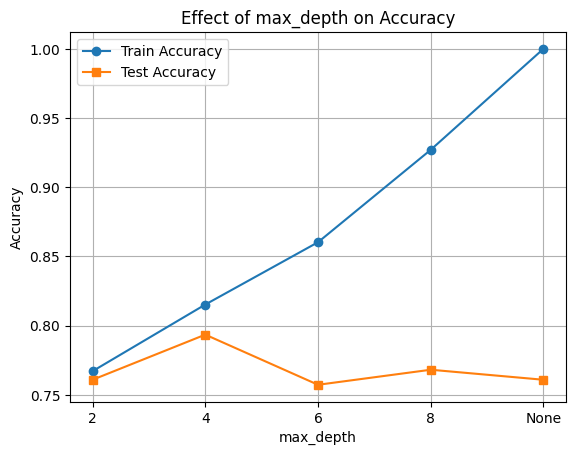

In [ ]:
depths = [2, 4, 6, 8, None]
train_scores, test_scores = [], []

for depth in depths:
    clf = DecisionTreeClassifier(max_depth=depth, random_state=42)
    clf.fit(X_train, y_train)
    train_scores.append(clf.score(X_train, y_train))
    test_scores.append(clf.score(X_test, y_test))

depth_labels = [str(depth) if depth is not None else "None" for depth in depths]
plt.plot(depth_labels, train_scores, marker="o", label="Train Accuracy")
plt.plot(depth_labels, test_scores, marker="s", label="Test Accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Effect of max_depth on Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## ✂️ Hyperparameter 2: `min_samples_split`

This parameter defines the **minimum number of samples required to split an internal node**.

- Higher values prevent the tree from splitting too soon, which can reduce overfitting.
- Lower values allow the tree to grow deeper, which can increase accuracy but also risk overfitting.

Let's observe how changing `min_samples_split` impacts model performance.


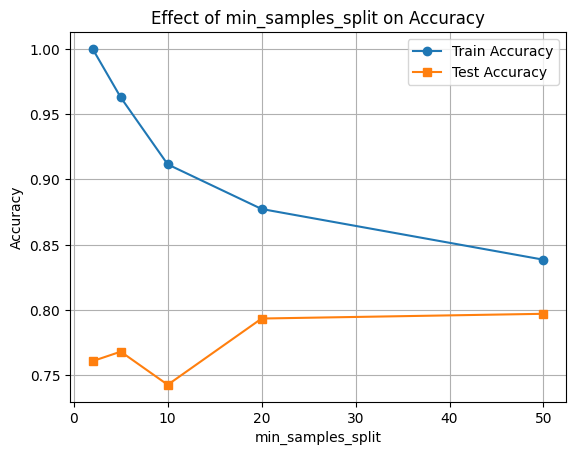

In [ ]:
min_samples = [2, 5, 10, 20, 50]
train_scores, test_scores = [], []

for min_split in min_samples:
    clf = DecisionTreeClassifier(min_samples_split=min_split, random_state=42)
    clf.fit(X_train, y_train)
    train_scores.append(clf.score(X_train, y_train))
    test_scores.append(clf.score(X_test, y_test))

plt.plot(min_samples, train_scores, marker="o", label="Train Accuracy")
plt.plot(min_samples, test_scores, marker="s", label="Test Accuracy")
plt.xlabel("min_samples_split")
plt.ylabel("Accuracy")
plt.title("Effect of min_samples_split on Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## 🍃 Hyperparameter 3: `min_samples_leaf`

This parameter controls the **minimum number of samples required to be at a leaf node**.

- It prevents the model from learning from very small subsets of data.
- Larger values make the model more conservative and help reduce overfitting.

We'll now test how different values for `min_samples_leaf` affect the performance of our Decision Tree.


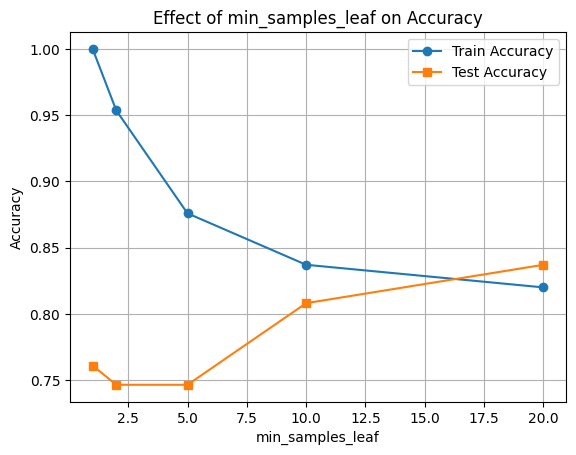

In [ ]:
min_leaves = [1, 2, 5, 10, 20]
train_scores, test_scores = [], []

for min_leaf in min_leaves:
    clf = DecisionTreeClassifier(min_samples_leaf=min_leaf, random_state=42)
    clf.fit(X_train, y_train)
    train_scores.append(clf.score(X_train, y_train))
    test_scores.append(clf.score(X_test, y_test))

plt.plot(min_leaves, train_scores, marker="o", label="Train Accuracy")
plt.plot(min_leaves, test_scores, marker="s", label="Test Accuracy")
plt.xlabel("min_samples_leaf")
plt.ylabel("Accuracy")
plt.title("Effect of min_samples_leaf on Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## ✅ Final Model with Selected Hyperparameters

We will now train one final tree using a moderate depth and larger leaves. These settings keep the tree readable and reduce overfitting.


In [ ]:
final_clf = DecisionTreeClassifier(
    max_depth=4,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=42,
)

final_clf.fit(X_train, y_train)

print(f"Train Accuracy: {final_clf.score(X_train, y_train):.3f}")
print(f"Test Accuracy: {final_clf.score(X_test, y_test):.3f}")


Train Accuracy: 0.800
Test Accuracy: 0.793


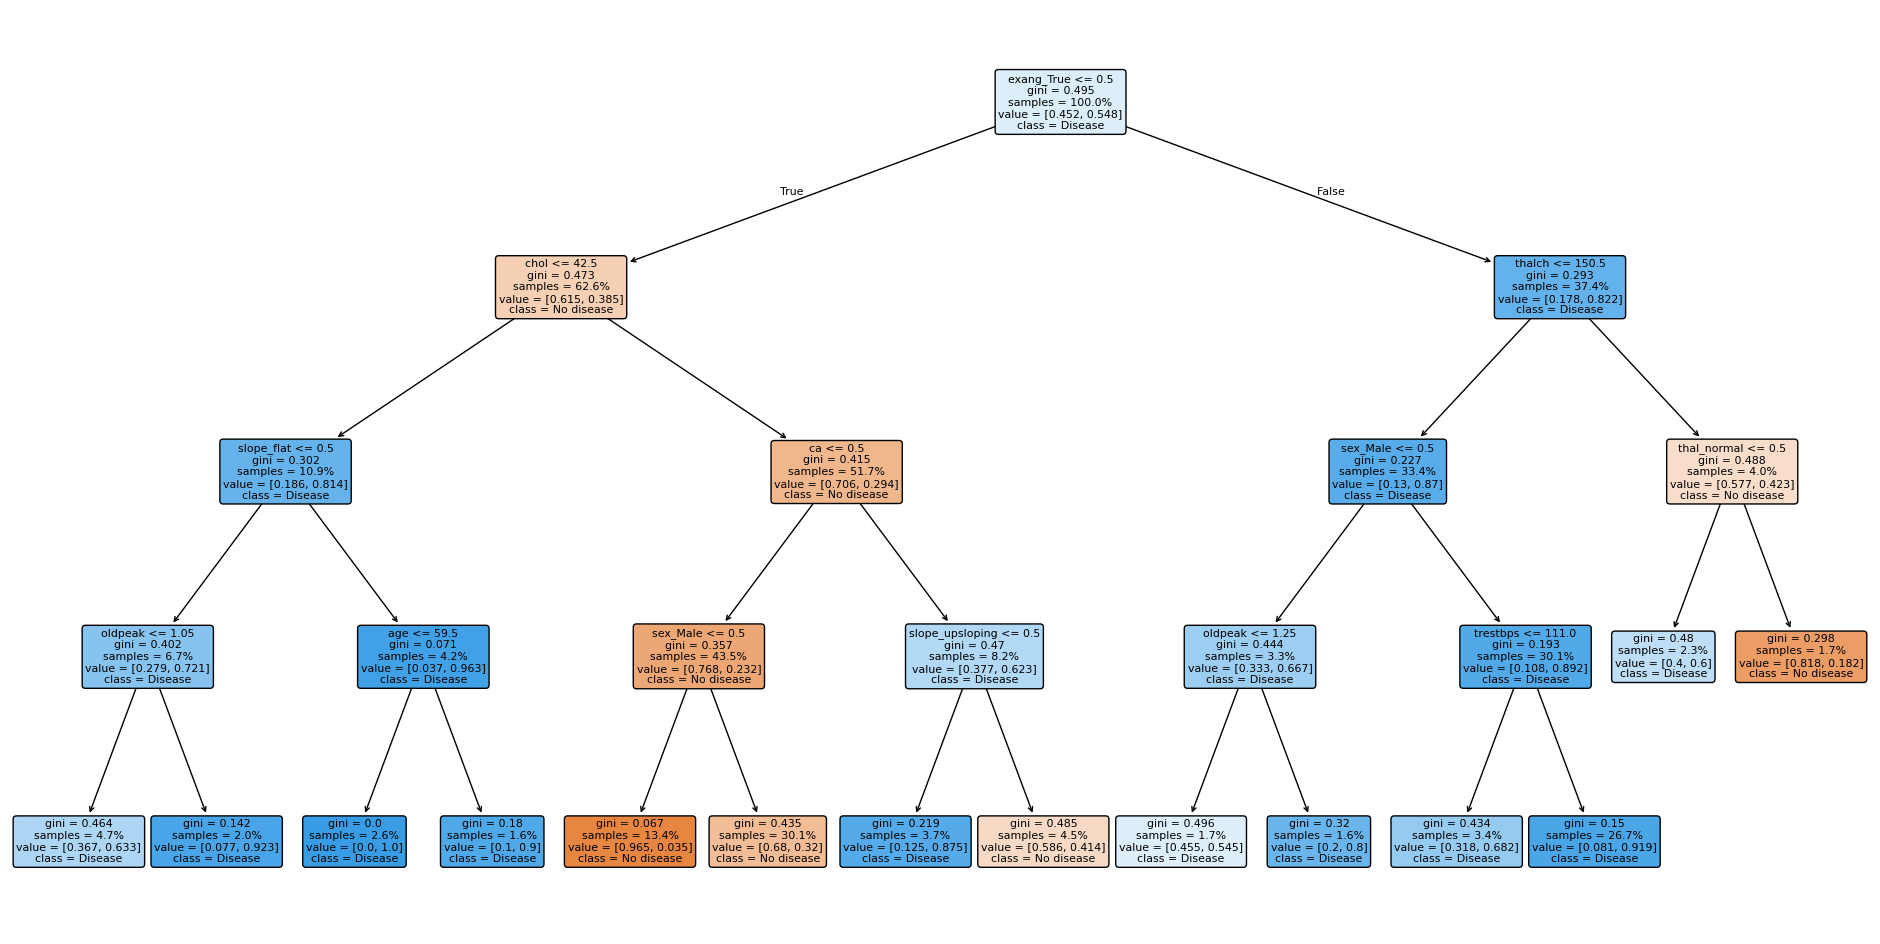

In [ ]:
plt.figure(figsize=(24, 12))
plot_tree(
    final_clf,
    feature_names=X_train.columns,
    class_names=["No disease", "Disease"],
    filled=True,
    rounded=True,
    proportion=True,
)
plt.show()


## Confusion Matrix
A confusion matrix is a table used to describe the performance of a classification model.

              precision    recall  f1-score   support

  No disease       0.71      0.88      0.79       120
     Disease       0.88      0.73      0.80       156

    accuracy                           0.79       276
   macro avg       0.80      0.80      0.79       276
weighted avg       0.81      0.79      0.79       276



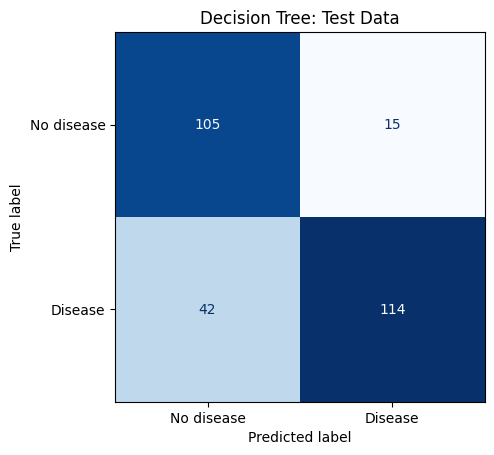

In [ ]:
y_pred = final_clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels=["No disease", "Disease"],
                                        cmap="Blues", colorbar=False)
plt.title("Decision Tree: Test Data")
plt.show()



## 🧠 Feature Importance with SHAP

SHAP helps us see which features influence the model's predictions.

### 📊 Interpreting the SHAP Summary Plot

| Element | Description |
|---|---|
| **Y-axis** | The most influential features appear at the top. |
| **X-axis** | Positive values push toward “disease”; negative values push toward “no disease”. |
| **Each dot** | One patient record. |
| **Colour** | Red means a higher feature value; blue means a lower value. |

The plot explains the model, but it does not prove that a feature causes heart disease.


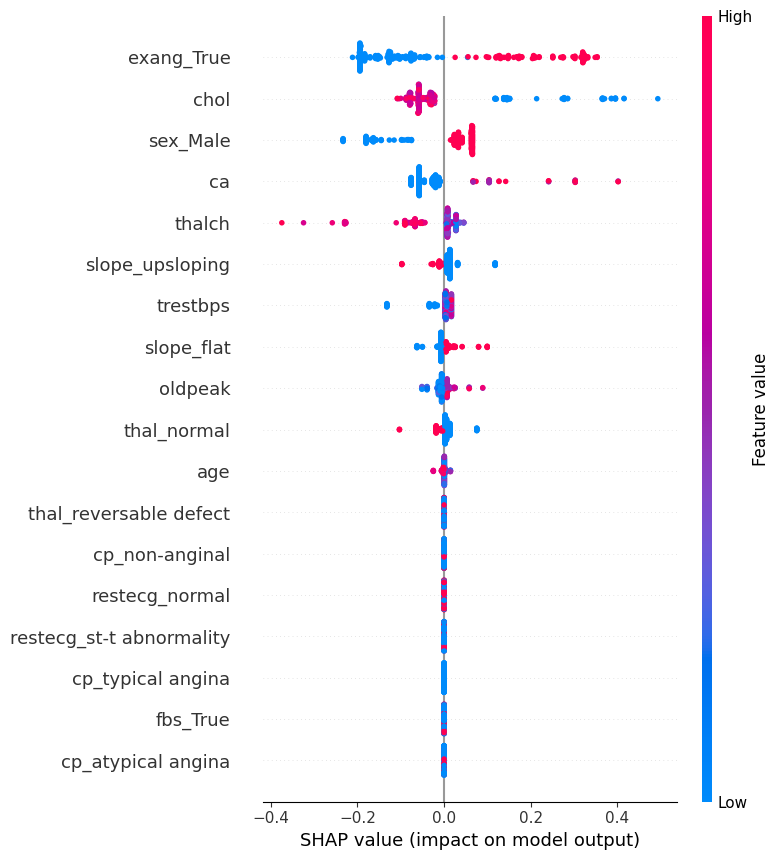

In [ ]:

# Create the SHAP explainer
explainer = shap.TreeExplainer(final_clf)

# Compute SHAP values for test data
shap_values = explainer(X_test)

# Select class 1: Disease (you need this handling for classification, not regression. since you must select the class you want to explain.)
disease_shap_values = shap_values[:, :, 1]

shap.summary_plot(disease_shap_values, X_test)

# plot onle the top features
# shap.plots.beeswarm(disease_shap_values)